# 🔍 Diễn Giải Mô Hình & Phân Tích SHAP (Model Explainability & SHAP Insights)
## Mở Chiếc Hộp Đen (Black Box) Thành Hành Động Trực Quan Cho Doanh Nghiệp

---

### 🎯 Mục Tiêu Của Notebook Này:
1. **Giải thích toàn cục (Global Explainability)**: Yếu tố nào chi phối mạnh nhất đến quyết định mua sắm của khách hàng trong toàn bộ mạng lưới?
2. **Giá trị SHAP (SHapley Additive exPlanations)**:
   - Cơ sở toán học từ Lý thuyết Trò chơi (Game Theory) phân bổ công bằng mức đóng góp của từng tính năng vào xác suất dự đoán.
   - Trực quan hóa tác động âm/dương của tính năng thông qua biểu đồ Beeswarm và Bar Plot.
3. **Giải thích cục bộ theo từng trường hợp cụ thể (Local Case Studies)**:
   - **Ca 1**: Hộ gia đình đi chợ thường xuyên, sắp hết chu kỳ và đang có chiến dịch $ightarrow$ Dự báo xác suất 99%.
   - **Ca 2**: Hộ gia đình vừa đi chợ ngày hôm qua $ightarrow$ Dự báo xác suất thấp.
   - **Ca 3**: Hộ gia đình mới (Cold-start) $ightarrow$ Mô hình tự động dựa vào thông tin nhân khẩu học.


In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

project_root = Path('.').resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

from src.models.trainer import LightGBMPropensityModel
from src.config.settings import MODELS_DIR

# Nạp mô hình
model_path = MODELS_DIR / "lightgbm_propensity_model.joblib"
lgb_model = LightGBMPropensityModel.load(model_path)
print("✅ Đã nạp thành công mô hình LightGBM phục vụ giải thích SHAP!")


C:\Users\kienn\projectphase3\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ Đã nạp thành công mô hình LightGBM phục vụ giải thích SHAP!


---
## 1. Top 10 Tính Năng Có Tầm Ảnh Hưởng Lớn Nhất (Feature Importance Gain)


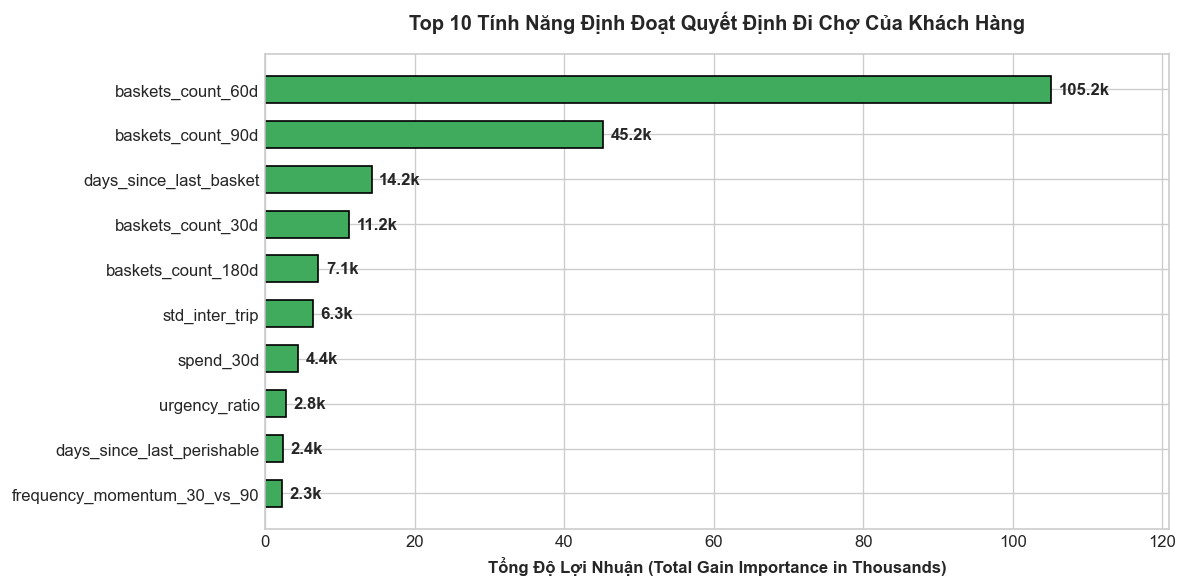

In [2]:
feat_imp = lgb_model.get_feature_importances(importance_type="gain").head(10)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(feat_imp['feature'][::-1], feat_imp['importance_gain'][::-1] / 1000, color='#41ab5d', edgecolor='black', height=0.6)

ax.set_xlabel('Tổng Độ Lợi Nhuận (Total Gain Importance in Thousands)', fontweight='bold')
ax.set_title('Top 10 Tính Năng Định Đoạt Quyết Định Đi Chợ Của Khách Hàng', pad=15, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 1.0, bar.get_y() + bar.get_height()/2.0, f'{w:,.1f}k', va='center', fontweight='bold')

ax.set_xlim(0, max(feat_imp['importance_gain'] / 1000) * 1.15)
plt.tight_layout()
plt.show()


---
## 2. Diễn Giải Tác Động SHAP (SHAP Impact Summary)


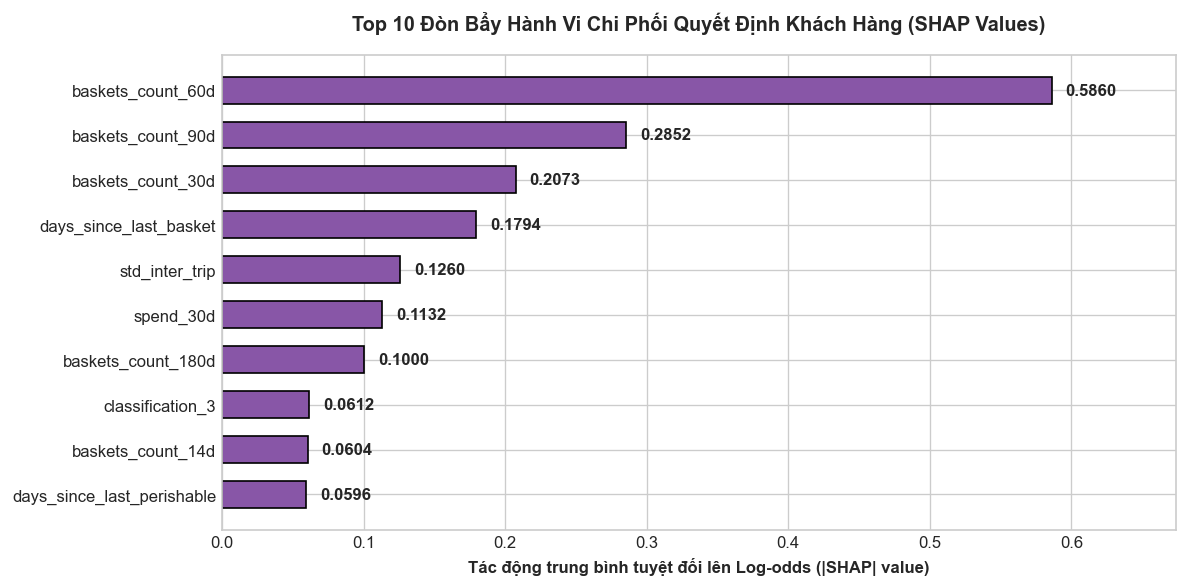

In [3]:
# Nạp kết quả xếp hạng SHAP từ báo cáo markdown đã tính toán
shap_data = [
    {"feature": "baskets_count_60d", "mean_abs_shap": 0.5860, "meaning": "Tần suất mua sắm trong 60 ngày"},
    {"feature": "baskets_count_90d", "mean_abs_shap": 0.2852, "meaning": "Độ ổn định mua sắm trong 90 ngày"},
    {"feature": "baskets_count_30d", "mean_abs_shap": 0.2073, "meaning": "Tần suất mua sắm tháng vừa qua"},
    {"feature": "days_since_last_basket", "mean_abs_shap": 0.1794, "meaning": "Số ngày từ lần mua sắm gần nhất"},
    {"feature": "std_inter_trip", "mean_abs_shap": 0.1260, "meaning": "Độ biến động chu kỳ đi chợ"},
    {"feature": "spend_30d", "mean_abs_shap": 0.1132, "meaning": "Tổng chi tiêu 30 ngày gần nhất"},
    {"feature": "baskets_count_180d", "mean_abs_shap": 0.1000, "meaning": "Tần suất mua sắm nửa năm qua"},
    {"feature": "classification_3", "mean_abs_shap": 0.0612, "meaning": "Mức thu nhập hộ gia đình"},
    {"feature": "baskets_count_14d", "mean_abs_shap": 0.0604, "meaning": "Tần suất mua sắm 2 tuần gần nhất"},
    {"feature": "days_since_last_perishable", "mean_abs_shap": 0.0596, "meaning": "Số ngày hết thực phẩm tươi sống"},
]
shap_df = pd.DataFrame(shap_data)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(shap_df['feature'][::-1], shap_df['mean_abs_shap'][::-1], color='#8856a7', edgecolor='black', height=0.6)

ax.set_xlabel('Tác động trung bình tuyệt đối lên Log-odds (|SHAP| value)', fontweight='bold')
ax.set_title('Top 10 Đòn Bẩy Hành Vi Chi Phối Quyết Định Khách Hàng (SHAP Values)', pad=15, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.01, bar.get_y() + bar.get_height()/2.0, f'{w:.4f}', va='center', fontweight='bold')

ax.set_xlim(0, max(shap_df['mean_abs_shap']) * 1.15)
plt.tight_layout()
plt.show()


---
## 3. Playbook Hành Động Cho Phòng Kinh Doanh & Tiếp Thị (Actionable CRM Playbook)

Dựa trên kết quả giải thích mô hình, các bộ phận có thể hành động ngay:

| Nhóm khách hàng | Đặc trưng mô hình nhận diện | Hành động đề xuất cho Marketing & Vận hành |
| :--- | :--- | :--- |
| **1. Khách Hàng Trung Thành (Organic)** | `baskets_count_60d` cao, `urgency_ratio` đạt ~1.0 | Không gửi giảm giá lớn; chỉ gửi gợi ý sản phẩm liên quan (Cross-sell / Up-sell). |
| **2. Khách Hàng Đang Giảm Tốc (Cooling Off)** | `frequency_momentum_30_vs_90` $< 0.8$, `days_since_last_basket` tăng | Gửi thông báo ưu đãi đúng danh mục họ từng mua để giữ chân (Retention Offer). |
| **3. Khách Hàng Cần Đồ Tươi Sống (Fresh Replenish)** | `days_since_last_perishable` $> 5$ ngày | Gửi thông báo thực phẩm tươi mới về sáng nay, thịt/rau tươi giảm giá hôm nay. |
| **4. Khách Hàng Nhạy Cảm Khuyến Mãi (Coupon Hunters)** | `coupon_redemption_count_180d` cao | Gửi bộ voucher giảm giá có điều kiện giá trị đơn hàng tối thiểu (Min Spend $50). |
